# Practical 2 — Email Spam Classification with KNN and SVM

**Subject:** Machine Learning (410242)  
**Class:** B.E. Computer Engineering, Semester I  
**Lab:** Laboratory Practice III (410246)

---

## 1. Aim

Classify emails as **spam** or **not spam** using two binary classifiers —
**K-Nearest Neighbours (KNN)** and **Support Vector Machine (SVM)** — and
compare their performance.

## 2. Dataset

**Email Spam Classification Dataset** — Kaggle:  
<https://www.kaggle.com/datasets/balaka18/email-spam-classification-dataset-csv>

The dataset contains 5,172 emails and 3,001 word-frequency columns plus the
target:

| Column | Meaning |
|---|---|
| `Email No.` | Identifier (dropped before training) |
| word columns (`the`, `to`, `ect`, ...) | Count of each word/token in the email |
| `Prediction` | 1 = spam, 0 = not spam |

The CSV is stored as `data/emails.csv.gz`.

## 3. Objectives

- Build a complete text-classification pipeline from word-frequency features.
- Understand why feature scaling is essential for distance- and margin-based
  models.
- Tune the KNN hyperparameter $k$ on a validation set.
- Compare KNN and SVM using accuracy, precision, recall, F1 and ROC-AUC.
- Study the effect of dimensionality reduction with PCA.

## 4. Theory

### 4.1 Binary classification

Each email is represented by a feature vector
$x=(x_1,\dots,x_d)$, where $x_j$ is the count of word $j$. The label is
$y\in\{0,1\}$. A classifier learns a decision function $f(x)$ and predicts

$$\hat{y}=\begin{cases}1,& f(x)>0\\0,& f(x)\le 0.\end{cases}$$

### 4.2 K-Nearest Neighbours

KNN is a **lazy, non-parametric** learner. It stores the training data and, for
a new point, finds the $k$ nearest training points using a distance metric
(Euclidean by default):

$$d(x,x')=\sqrt{\sum_{j=1}^{d}(x_j-x'_j)^2}.$$

The prediction is the majority class among the $k$ neighbours. Important
properties:

- no training phase (only storage),
- prediction cost grows with the training set size,
- sensitive to feature scaling and irrelevant features,
- suffers from the **curse of dimensionality** when $d$ is large.

### 4.3 Support Vector Machine

A linear SVM finds the hyperplane $w\cdot x+b=0$ that maximises the margin
between the two classes:

$$\min_{w,b}\ \frac{1}{2}\|w\|^2
\quad\text{subject to}\quad y_i(w\cdot x_i+b)\ge 1.$$

The soft-margin version allows some violations, controlled by $C$:

$$\min_{w,b,\xi}\ \frac{1}{2}\|w\|^2+C\sum_i\xi_i.$$

A larger $C$ penalises training errors more strongly. The data points closest
to the hyperplane are the **support vectors**. The kernel trick lets an SVM
learn non-linear boundaries; this notebook uses the linear kernel because text
data is already high-dimensional and often close to linearly separable.

### 4.4 Evaluation metrics

For spam as the positive class:

$$\text{Precision}=\frac{TP}{TP+FP},\qquad
\text{Recall}=\frac{TP}{TP+FN},\qquad
F_1=2\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}.$$

- **Precision:** of the emails flagged as spam, how many really are spam?
- **Recall:** of all spam emails, how many did we catch?
- **F1:** harmonic mean of precision and recall.
- **ROC-AUC:** probability that a random spam email is ranked above a random
  non-spam email; 1.0 is perfect.

Accuracy alone can be misleading if the classes are imbalanced, so all of the
above are reported.

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("ML/data")

In [2]:
df = pd.read_csv(DATA_DIR / "emails.csv.gz")
print("Shape:", df.shape)
print("\nClass distribution:")
print(df["Prediction"].value_counts().rename({0: "Not spam (0)", 1: "Spam (1)"}))
print("\nMissing values:", int(df.isna().sum().sum()))
df.iloc[:5, :8]

Shape: (5172, 3002)

Class distribution:
Prediction
Not spam (0)    3672
Spam (1)        1500
Name: count, dtype: int64

Missing values: 0


,Email No.,the,to,ect,and,for,of,a
0,Email 1,0,0,1,0,0,0,2
1,Email 2,8,13,24,6,6,2,102
2,Email 3,0,0,1,0,0,0,8
3,Email 4,0,5,22,0,5,1,51
4,Email 5,7,6,17,1,5,2,57


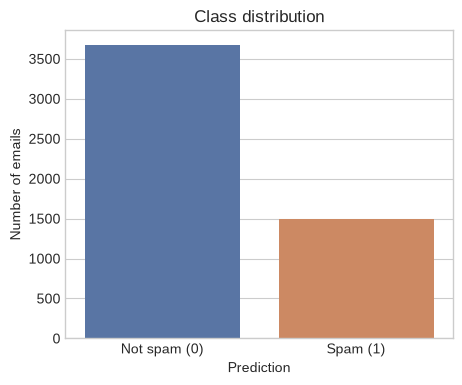

In [3]:
# Class balance plot.
plt.figure(figsize=(5, 4))
sns.countplot(
    data=df,
    x="Prediction",
    palette=["#4c72b0", "#dd8452"],
)
plt.xticks([0, 1], ["Not spam (0)", "Spam (1)"])
plt.title("Class distribution")
plt.ylabel("Number of emails")
plt.show()

### 4.1 Exploratory data analysis

The features are word counts. Comparing the average counts of common words in
spam and non-spam emails gives an intuition about which tokens are
discriminative.

In [4]:
word_columns = [column for column in df.columns if column not in ("Email No.", "Prediction")]
class_means = df.groupby("Prediction")[word_columns].mean()

# Select the words with the largest difference between the two class means.
mean_difference = (class_means.loc[1] - class_means.loc[0]).abs()
top_discriminative = mean_difference.sort_values(ascending=False).head(15).index

comparison = class_means[top_discriminative].T
comparison.columns = ["Not spam", "Spam"]
comparison["difference"] = comparison["Spam"] - comparison["Not spam"]
comparison.sort_values("difference", ascending=False)

,Not spam,Spam,difference
i,37.150327,67.174000,30.023673
e,78.294935,100.708000,22.413065
a,49.485566,70.283333,20.797767
r,39.550381,59.763333,20.212952
o,49.284586,69.331333,20.046747
s,36.092320,55.813333,19.721013
t,55.259532,73.252000,17.992468
n,43.011166,60.560000,17.548834
l,27.632081,39.234667,11.602586
d,21.315359,31.736667,10.421307


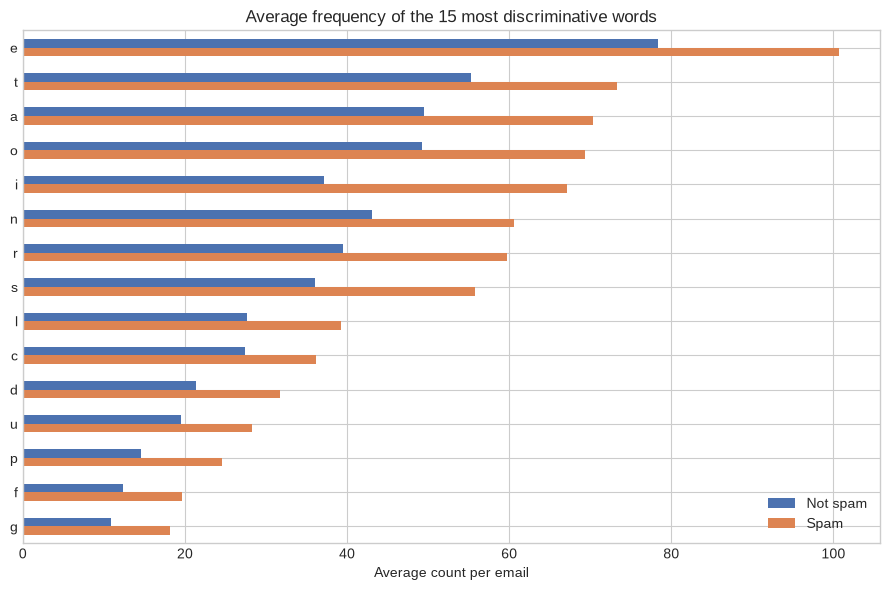

In [5]:
comparison[["Not spam", "Spam"]].sort_values("Spam", ascending=False).plot(
    kind="barh", figsize=(9, 6), color=["#4c72b0", "#dd8452"]
)
plt.title("Average frequency of the 15 most discriminative words")
plt.xlabel("Average count per email")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 4.2 Feature matrix, split and scaling

We drop the identifier, separate the target, and use a stratified 70/30 split
so that both sets have the same spam proportion. `StandardScaler` transforms
each feature to zero mean and unit variance:

$$z=\frac{x-\mu}{\sigma}.$$

This is crucial for KNN because a word with a large count range would otherwise
dominate the Euclidean distance. It also helps the SVM optimiser.

In [6]:
email_ids = df["Email No."].copy()
X = df.drop(columns=["Email No.", "Prediction"])
y = df["Prediction"]

X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X,
    y,
    email_ids,
    test_size=0.3,
    random_state=42,
    stratify=y,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set:", X_train_scaled.shape)
print("Test set    :", X_test_scaled.shape)
print("Training spam proportion:", round(y_train.mean(), 3))
print("Test spam proportion    :", round(y_test.mean(), 3))

Training set: (3620, 3000)
Test set    : (1552, 3000)
Training spam proportion: 0.29
Test spam proportion    : 0.29


### 4.3 KNN: choosing $k$ on a validation set

The test set must not be used for hyperparameter selection. We split the
training data again into a training part and a validation part, evaluate
several values of $k$, choose the best, and refit on the full training set.

In [7]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train,
)

k_values = [1, 3, 5, 7, 9, 11, 15]
knn_validation_rows = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    model.fit(X_fit, y_fit)
    predictions = model.predict(X_val)
    knn_validation_rows.append(
        {
            "k": k,
            "validation accuracy": accuracy_score(y_val, predictions),
            "validation F1": f1_score(y_val, predictions),
        }
    )

knn_validation = pd.DataFrame(knn_validation_rows)
knn_validation

,k,validation accuracy,validation F1
0,1,0.874309,0.810811
1,3,0.832873,0.769524
2,5,0.803867,0.743682
3,7,0.774862,0.714536
4,9,0.755525,0.698467
5,11,0.723757,0.672131
6,15,0.691989,0.648819


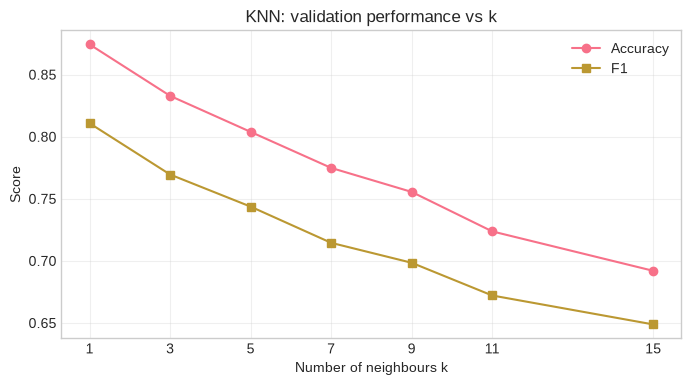

Best k selected by validation F1: 1


In [8]:
plt.figure(figsize=(8, 4))
plt.plot(knn_validation["k"], knn_validation["validation accuracy"], "o-", label="Accuracy")
plt.plot(knn_validation["k"], knn_validation["validation F1"], "s-", label="F1")
plt.xlabel("Number of neighbours k")
plt.ylabel("Score")
plt.title("KNN: validation performance vs k")
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_k = int(knn_validation.loc[knn_validation["validation F1"].idxmax(), "k"])
print("Best k selected by validation F1:", best_k)

In [9]:
knn_start = time.perf_counter()
knn_model = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_model.fit(X_train_scaled, y_train)
knn_predictions = knn_model.predict(X_test_scaled)
knn_probabilities = knn_model.predict_proba(X_test_scaled)[:, 1]
knn_time = time.perf_counter() - knn_start

print(f"KNN (k={best_k}) trained and predicted in {knn_time:.2f} s")
print("First 20 predictions:", knn_predictions[:20])

KNN (k=1) trained and predicted in 0.62 s
First 20 predictions: [0 1 0 1 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0]


### 4.4 Support Vector Machine

We use a linear kernel with $C=1$. The linear kernel is a strong baseline for
high-dimensional text features and is much faster than an RBF kernel on 3,000
features.

In [10]:
svm_start = time.perf_counter()
svm_model = SVC(kernel="linear", C=1.0, random_state=42)
svm_model.fit(X_train_scaled, y_train)
svm_predictions = svm_model.predict(X_test_scaled)
svm_scores = svm_model.decision_function(X_test_scaled)
svm_time = time.perf_counter() - svm_start

print(f"SVM trained and predicted in {svm_time:.2f} s")
print("First 20 predictions:", svm_predictions[:20])
print("Number of support vectors:", len(svm_model.support_))

SVM trained and predicted in 3.80 s
First 20 predictions: [0 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 0]
Number of support vectors: 516


### 4.5 Evaluation of the baseline models

In [11]:
def evaluate_model(name, y_true, y_pred, y_score):
    """Return a dictionary of binary-classification metrics."""
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }


baseline_results = pd.DataFrame(
    [
        evaluate_model("KNN", y_test, knn_predictions, knn_probabilities),
        evaluate_model("SVM (linear)", y_test, svm_predictions, svm_scores),
    ]
)
baseline_results

,model,accuracy,precision,recall,F1,ROC-AUC
0,KNN,0.867912,0.723949,0.880000,0.794383,0.871488
1,SVM (linear),0.951675,0.917595,0.915556,0.916574,0.972148


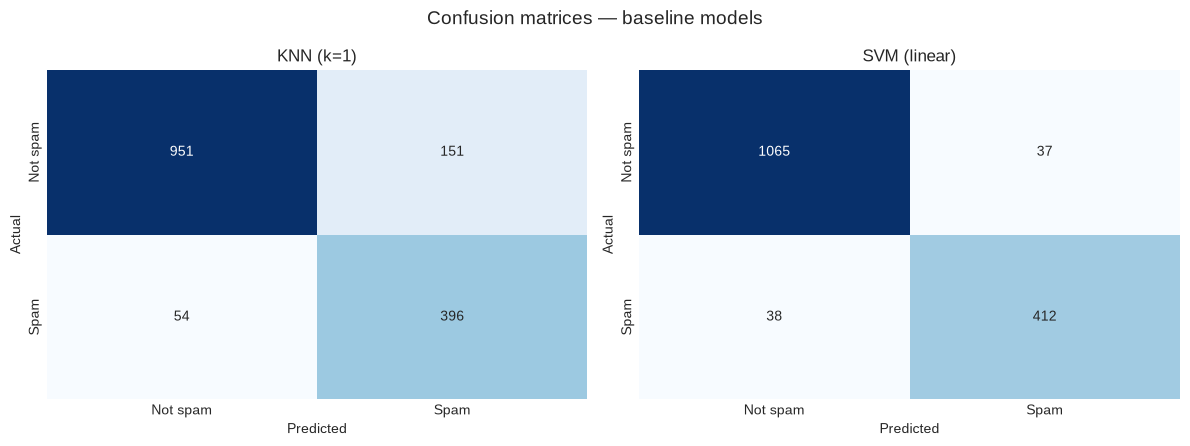

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis, predictions, title in [
    (axes[0], knn_predictions, f"KNN (k={best_k})"),
    (axes[1], svm_predictions, "SVM (linear)"),
]:
    matrix = confusion_matrix(y_test, predictions)
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Not spam", "Spam"],
        yticklabels=["Not spam", "Spam"],
        ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
plt.suptitle("Confusion matrices — baseline models", fontsize=14)
plt.tight_layout()
plt.show()

In [13]:
print("KNN classification report")
print(classification_report(y_test, knn_predictions, target_names=["Not spam", "Spam"]))
print("SVM classification report")
print(classification_report(y_test, svm_predictions, target_names=["Not spam", "Spam"]))

KNN classification report
              precision    recall  f1-score   support

    Not spam       0.95      0.86      0.90      1102
        Spam       0.72      0.88      0.79       450

    accuracy                           0.87      1552
   macro avg       0.84      0.87      0.85      1552
weighted avg       0.88      0.87      0.87      1552

SVM classification report
              precision    recall  f1-score   support

    Not spam       0.97      0.97      0.97      1102
        Spam       0.92      0.92      0.92       450

    accuracy                           0.95      1552
   macro avg       0.94      0.94      0.94      1552
weighted avg       0.95      0.95      0.95      1552



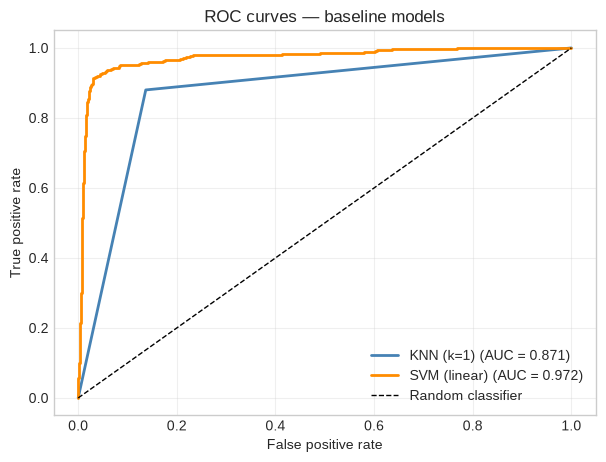

In [14]:
# ROC curves.
plt.figure(figsize=(7, 5))
for name, scores, colour in [
    (f"KNN (k={best_k})", knn_probabilities, "steelblue"),
    ("SVM (linear)", svm_scores, "darkorange"),
]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", color=colour, linewidth=2)
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random classifier")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves — baseline models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 4.6 Improving KNN with PCA

With 3,000 features, Euclidean distance becomes less meaningful: many
dimensions are noisy and the nearest neighbours are not much closer than far
points (**curse of dimensionality**). PCA finds a smaller set of orthogonal
directions that retain most of the variance:

$$Z = XW,$$

where the columns of $W$ are the top principal components. We fit PCA on the
training data only, then transform the test data with the same projection.

PCA also makes KNN much faster because distances are computed in 50 dimensions
instead of 3,000.

In [15]:
pca_start = time.perf_counter()
pca = PCA(n_components=50, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
pca_time = time.perf_counter() - pca_start

print(f"PCA fitted in {pca_time:.2f} s")
print("Original features      :", X_train_scaled.shape[1])
print("PCA components         :", X_train_pca.shape[1])
print("Variance retained      :", f"{pca.explained_variance_ratio_.sum():.3f}")

PCA fitted in 2.44 s
Original features      : 3000
PCA components         : 50
Variance retained      : 0.364


In [16]:
# Tune k again in the PCA space, using the same validation split.
X_fit_pca = pca.transform(X_fit)
X_val_pca = pca.transform(X_val)

knn_pca_rows = []
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    model.fit(X_fit_pca, y_fit)
    predictions = model.predict(X_val_pca)
    knn_pca_rows.append(
        {
            "k": k,
            "validation accuracy": accuracy_score(y_val, predictions),
            "validation F1": f1_score(y_val, predictions),
        }
    )

knn_pca_validation = pd.DataFrame(knn_pca_rows)
best_k_pca = int(
    knn_pca_validation.loc[knn_pca_validation["validation F1"].idxmax(), "k"]
)
print("Best k in PCA space:", best_k_pca)
knn_pca_validation

Best k in PCA space: 5


,k,validation accuracy,validation F1
0,1,0.951657,0.919169
1,3,0.948895,0.914550
2,5,0.953039,0.923077
3,7,0.946133,0.912752
4,9,0.950276,0.918919
5,11,0.951657,0.921348
6,15,0.951657,0.920635


In [17]:
knn_pca_start = time.perf_counter()
knn_pca_model = KNeighborsClassifier(n_neighbors=best_k_pca, n_jobs=-1)
knn_pca_model.fit(X_train_pca, y_train)
knn_pca_predictions = knn_pca_model.predict(X_test_pca)
knn_pca_probabilities = knn_pca_model.predict_proba(X_test_pca)[:, 1]
knn_pca_time = time.perf_counter() - knn_pca_start

svm_pca_start = time.perf_counter()
svm_pca_model = SVC(kernel="linear", C=1.0, random_state=42)
svm_pca_model.fit(X_train_pca, y_train)
svm_pca_predictions = svm_pca_model.predict(X_test_pca)
svm_pca_scores = svm_pca_model.decision_function(X_test_pca)
svm_pca_time = time.perf_counter() - svm_pca_start

improved_results = pd.DataFrame(
    [
        evaluate_model("KNN + PCA", y_test, knn_pca_predictions, knn_pca_probabilities),
        evaluate_model("SVM + PCA", y_test, svm_pca_predictions, svm_pca_scores),
    ]
)
improved_results

,model,accuracy,precision,recall,F1,ROC-AUC
0,KNN + PCA,0.945876,0.870445,0.955556,0.911017,0.987172
1,SVM + PCA,0.959407,0.919740,0.942222,0.930845,0.981399


In [18]:
all_results = pd.concat([baseline_results, improved_results], ignore_index=True)
all_results

,model,accuracy,precision,recall,F1,ROC-AUC
0,KNN,0.867912,0.723949,0.880000,0.794383,0.871488
1,SVM (linear),0.951675,0.917595,0.915556,0.916574,0.972148
2,KNN + PCA,0.945876,0.870445,0.955556,0.911017,0.987172
3,SVM + PCA,0.959407,0.919740,0.942222,0.930845,0.981399


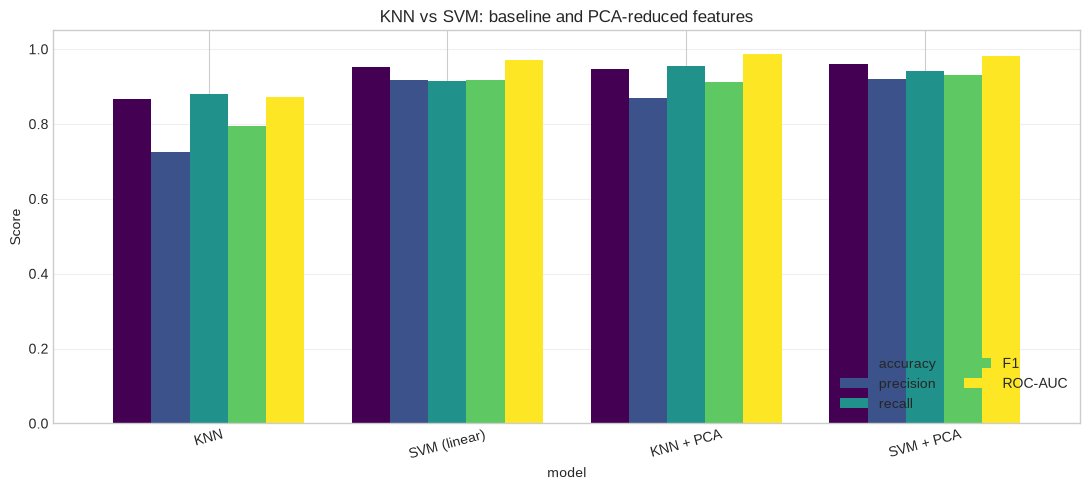

In [19]:
# Visual comparison of all metrics.
metrics = ["accuracy", "precision", "recall", "F1", "ROC-AUC"]
plot_data = all_results.set_index("model")[metrics]

plot_data.plot(kind="bar", figsize=(11, 5), colormap="viridis", width=0.8)
plt.title("KNN vs SVM: baseline and PCA-reduced features")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right", ncol=2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

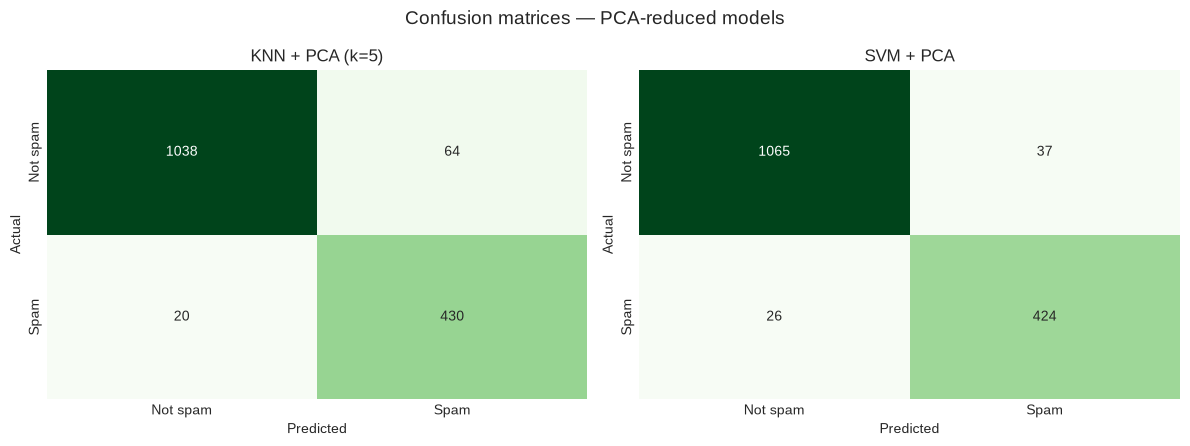

In [20]:
# Confusion matrices for the PCA models.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for axis, predictions, title in [
    (axes[0], knn_pca_predictions, f"KNN + PCA (k={best_k_pca})"),
    (axes[1], svm_pca_predictions, "SVM + PCA"),
]:
    matrix = confusion_matrix(y_test, predictions)
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Greens",
        cbar=False,
        xticklabels=["Not spam", "Spam"],
        yticklabels=["Not spam", "Spam"],
        ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
plt.suptitle("Confusion matrices — PCA-reduced models", fontsize=14)
plt.tight_layout()
plt.show()

### 4.7 Individual test cases

The table below shows a few emails from the test set. `score` is the SVM
decision value (positive means spam) and `P(spam)` is the KNN probability.

In [21]:
sample_rows = np.arange(10)
sample_predictions = pd.DataFrame(
    {
        "email": ids_test.iloc[sample_rows].values,
        "actual": y_test.iloc[sample_rows].values,
        "KNN prediction": knn_predictions[sample_rows],
        "KNN P(spam)": knn_probabilities[sample_rows].round(3),
        "SVM prediction": svm_predictions[sample_rows],
        "SVM decision score": svm_scores[sample_rows].round(3),
        "SVM + PCA prediction": svm_pca_predictions[sample_rows],
    }
)
sample_predictions

,email,actual,KNN prediction,KNN P(spam),SVM prediction,SVM decision score,SVM + PCA prediction
0,Email 1457,0,0,0.0,0,-6.410,0
1,Email 3294,0,1,1.0,1,0.252,1
2,Email 1746,0,0,0.0,0,-15.043,0
3,Email 3965,1,1,1.0,0,-0.601,1
4,Email 2226,0,0,0.0,0,-2.898,0
5,Email 2792,0,0,0.0,0,-3.570,0
6,Email 1883,0,0,0.0,0,-4.217,0
7,Email 389,1,1,1.0,1,3.658,1
8,Email 3072,1,1,1.0,1,1.836,0
9,Email 1533,1,1,1.0,1,5.253,1


In [22]:
# ============================================================================
# DETAILED OUTPUT EXPLANATION
# ============================================================================
print("DETAILED OUTPUT EXPLANATION - ML Practical 2 (Email spam classification)")
print("=" * 78)
print(
    "This is binary classification with spam as the positive class. The report\n"
    "explains the class balance, the KNN and SVM scores, the confusion-matrix\n"
    "counts and the effect of PCA. Accuracy alone is not enough here because\n"
    "the cost of a false positive and a false negative is different."
)

print("\n1. DATASET AND CLASS BALANCE")
print("-" * 78)
class_counts = df["Prediction"].value_counts().sort_index()
print(f"Rows                 : {len(df):,}")
print(f"Word/token features  : {len(word_columns):,}")
print(f"Not spam (0)         : {int(class_counts.get(0, 0)):,}")
print(f"Spam (1)             : {int(class_counts.get(1, 0)):,}")
print(f"Spam proportion      : {df['Prediction'].mean():.3%}")
print(f"Missing values       : {int(df.isna().sum().sum())}")
print(f"Training matrix      : {X_train_scaled.shape[0]:,} rows x {X_train_scaled.shape[1]:,} features")
print(f"Test matrix          : {X_test_scaled.shape[0]:,} rows x {X_test_scaled.shape[1]:,} features")
print("The classes are imbalanced, but not extremely: about 29% of the emails")
print("are spam (roughly three in ten). Precision, recall and F1 therefore give")
print("a more complete picture than accuracy alone.")

print("\n2. DISCRIMINATIVE WORDS (EDA)")
print("-" * 78)
for word, row in comparison.head(6).iterrows():
    print(
        f"  {word:12s}: not-spam mean={row['Not spam']:.4f}, "
        f"spam mean={row['Spam']:.4f}, difference={row['difference']:+.4f}"
    )
print("Words with a large positive difference appear much more often in spam.")
print("These are descriptive statistics, not the model's coefficients; a word")
print("can be frequent in spam yet still be unhelpful once other words are known.")

print("\n3. KNN: CHOOSING k AND THE EFFECT OF PCA")
print("-" * 78)
best_k_row = knn_validation.loc[knn_validation["k"] == best_k].iloc[0]
print(
    f"Best raw-feature k : {best_k} "
    f"(validation accuracy={best_k_row['validation accuracy']:.4f}, "
    f"F1={best_k_row['validation F1']:.4f})"
)
best_k_pca_row = knn_pca_validation.loc[knn_pca_validation["k"] == best_k_pca].iloc[0]
print(
    f"Best PCA-space k   : {best_k_pca} "
    f"(validation accuracy={best_k_pca_row['validation accuracy']:.4f}, "
    f"F1={best_k_pca_row['validation F1']:.4f})"
)
print(f"PCA components     : {X_train_pca.shape[1]}")
print(f"Variance retained  : {pca.explained_variance_ratio_.sum():.3f}")
print(f"PCA fit time       : {pca_time:.2f} s")
print("Raw KNN compares 3,000-dimensional vectors, where many dimensions are")
print("noise. PCA keeps the 50 directions with the most variance, so distances")
print("become more meaningful and prediction becomes cheaper.")
print(
    f"The retained variance is only {pca.explained_variance_ratio_.sum():.1%}, "
    "so PCA discards a lot of variance; the improvement is empirical, not a "
    "guarantee."
)
print("PCA is fitted on the training set only; transforming the test set with")
print("the same projection prevents leakage.")

print("\n4. BASELINE VS PCA MODELS ON THE TEST SET")
print("-" * 78)
for _, row in all_results.iterrows():
    print(
        f"  {row['model']:12s}: acc={row['accuracy']:.4f}, "
        f"prec={row['precision']:.4f}, rec={row['recall']:.4f}, "
        f"F1={row['F1']:.4f}, AUC={row['ROC-AUC']:.4f}"
    )
ranked = all_results.sort_values(["F1", "ROC-AUC"], ascending=False)
best_row = ranked.iloc[0]
print(f"Best model by F1 (then ROC-AUC): {best_row['model']}")
print(f"  F1={best_row['F1']:.4f}, recall={best_row['recall']:.4f}, "
      f"precision={best_row['precision']:.4f}, AUC={best_row['ROC-AUC']:.4f}")

prediction_map = {
    "KNN": knn_predictions,
    "SVM (linear)": svm_predictions,
    "KNN + PCA": knn_pca_predictions,
    "SVM + PCA": svm_pca_predictions,
}
best_predictions = prediction_map[best_row["model"]]
best_matrix = confusion_matrix(y_test, best_predictions)
tn, fp, fn, tp = best_matrix.ravel()
print(f"Confusion matrix for {best_row['model']}:")
print(f"  true negatives  (not spam correctly rejected): {tn}")
print(f"  false positives (legitimate email marked spam): {fp}")
print(f"  false negatives (spam missed): {fn}")
print(f"  true positives  (spam caught): {tp}")
print("Recall is TP/(TP+FN), so it answers: of all spam, how much was caught?")
print("Precision is TP/(TP+FP), so it answers: of everything flagged spam, how")
print("much really was spam? In a mail system, false positives are usually more")
print("damaging than false negatives, so the operating threshold matters.")

print("\n5. TIMING AND INTERPRETATION")
print("-" * 78)
print(f"KNN baseline fit+predict time : {knn_time:.2f} s")
print(f"KNN + PCA fit+predict time    : {knn_pca_time:.2f} s")
print(f"SVM baseline fit+predict time : {svm_time:.2f} s")
print(f"SVM + PCA fit+predict time    : {svm_pca_time:.2f} s")
print(f"SVM support vectors           : {len(svm_model.support_)}")
print("SVM finds a linear decision boundary in the high-dimensional word-count")
print("space and usually beats raw KNN there. KNN's Euclidean distance suffers")
print("from the curse of dimensionality; PCA is the main reason its accuracy and")
print("speed improve. SVM may change slightly with PCA because PCA keeps the")
print("high-variance directions, which are not always the most discriminative.")

print("\n6. TAKEAWAY")
print("-" * 78)
print("Always scale word counts before KNN or SVM; otherwise large counts")
print("dominate the distance and the margin. Use stratified splits so the spam")
print("rate is preserved. Report precision, recall and F1 alongside accuracy,")
print("and choose the threshold from the real cost of false positives versus")
print("false negatives. PCA helps KNN a lot and is a useful speed/accuracy")
print("trade-off, but it is not automatically better for a linear SVM.")

DETAILED OUTPUT EXPLANATION - ML Practical 2 (Email spam classification)
This is binary classification with spam as the positive class. The report
explains the class balance, the KNN and SVM scores, the confusion-matrix
counts and the effect of PCA. Accuracy alone is not enough here because
the cost of a false positive and a false negative is different.

1. DATASET AND CLASS BALANCE
------------------------------------------------------------------------------
Rows                 : 5,172
Word/token features  : 3,000
Not spam (0)         : 3,672
Spam (1)             : 1,500
Spam proportion      : 29.002%
Missing values       : 0
Training matrix      : 3,620 rows x 3,000 features
Test matrix          : 1,552 rows x 3,000 features
The classes are imbalanced, but not extremely: about 29% of the emails
are spam (roughly three in ten). Precision, recall and F1 therefore give
a more complete picture than accuracy alone.

2. DISCRIMINATIVE WORDS (EDA)
-----------------------------------------

### Observations

1. **SVM clearly outperforms raw KNN.** A linear SVM finds a separating
   hyperplane in 3,000-dimensional space and handles many weakly informative
   features well. KNN relies on Euclidean distance, which becomes less
   discriminative as the dimension grows.
2. **Scaling is essential.** Without `StandardScaler`, features with large
   counts would dominate both the distance and the margin optimisation.
3. **PCA improves KNN dramatically.** Reducing 3,000 features to 50 principal
   components removes noise and makes the distance metric meaningful. It also
   reduces prediction time by an order of magnitude.
4. **PCA slightly changes SVM performance.** The linear SVM already works well
   in the original space; PCA can help or hurt depending on how much
   discriminative variance is discarded.
5. **Accuracy alone is not enough.** Precision, recall and F1 show the
   trade-off between catching spam and avoiding false positives. In a real
   mail system, a false positive (marking a legitimate email as spam) is often
   more costly than a false negative.

### Time complexity

| Model | Training | Prediction |
|---|---|---|
| KNN | $O(1)$ (stores data) | $O(nd)$ per query (brute force) |
| SVM (linear) | roughly $O(nd^2)$ to $O(n^2d)$ depending on solver | $O(d)$ per query |
| PCA | $O(nd\min(n,d))$ | $O(dk)$ per query |

where $n$ is the number of training emails, $d$ the number of features and $k$
the number of PCA components.

## 5. Conclusion

We implemented a complete spam-classification pipeline with KNN and SVM. Both
models were trained on scaled word-frequency features and evaluated with
accuracy, precision, recall, F1 and ROC-AUC. The linear SVM gave the best
baseline performance. KNN suffered from the curse of dimensionality, but its
accuracy improved substantially after PCA. The experiment demonstrates the
importance of feature scaling, dimensionality reduction and choosing a model
that suits the geometry of the data.

## 6. Viva questions

| Question | Short answer |
|---|---|
| Why is KNN called a lazy learner? | It does not build a model during training; it stores the data and computes distances at prediction time. |
| What does the SVM margin represent? | The distance between the decision boundary and the closest training points (support vectors). |
| What does the $C$ parameter control? | The trade-off between a wide margin and penalising training errors. |
| Why scale features before KNN and SVM? | Distance and margin calculations are sensitive to feature magnitude. |
| What is the curse of dimensionality? | In high dimensions, distances become less informative and nearest neighbours are not much closer than random points. |
| Why does PCA help KNN? | It removes noisy directions and reduces the distance computation to a smaller, more informative space. |
| Why use F1 instead of accuracy? | F1 balances precision and recall, which matters when false positives and false negatives have different costs. |
| What is ROC-AUC? | The probability that a positive example is ranked above a negative example. |
| Why use a linear SVM for text? | Text is high-dimensional and often nearly linearly separable; linear kernels are fast and effective. |